# Moving Average Crossover Strategy Backtest
This project evaluates historical performance of a 20/50-day Simple Moving Average (SMA) crossover strategy on the SPY ETF, using daily price data from 2015 to 2025. The strategy is benchmarked against buy-and-hold to access returns, risk-adjusted performance, and market exposure.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

### 1. Download historical market data

In [2]:
df = yf.download(
    "SPY",
    start = "2015-01-01",
    end = "2026-01-01",
    auto_adjust = True # adjusts OHLC prices for splits and dividends
)

close = df["Close"].squeeze()

print(df.head())
print(df.shape)

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker             SPY         SPY         SPY         SPY        SPY
Date                                                                 
2015-01-02  169.267517  170.462279  168.237558  170.050296  121465900
2015-01-05  166.210556  168.394063  165.905692  168.229272  169632600
2015-01-06  164.645050  167.034549  163.854036  166.515446  209151400
2015-01-07  166.696762  167.034592  165.518495  165.963432  125346700
2015-01-08  169.654770  169.869009  168.081003  168.097473  147217800
(2766, 5)


### 2. Visualise stock price

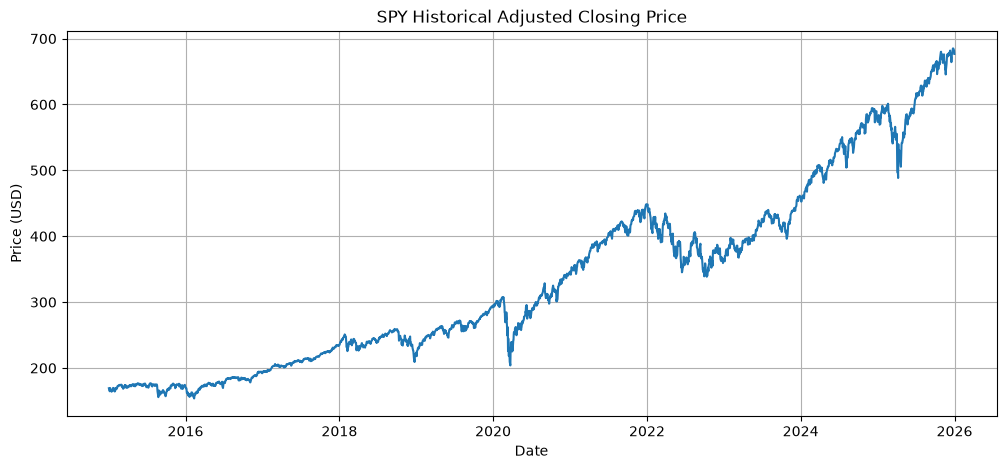

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(close)

plt.title("SPY Historical Adjusted Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.grid(True)
plt.show()

### 3. Calculate simple moving averages
- 20-day SMA: shorter-term price trends, reacts faster to recent price movements
- 50-day SMA: longer-term price trends, smoother
  
When shorter average rises above longer average, suggests that recent prices are relatively stronger than long-term trend

Note: MA are lagging indicators, they summarise historical prices rather than predicting future prices

In [4]:
df["SMA20"] = close.rolling(window=20).mean()
df["SMA50"] = close.rolling(window=50).mean()

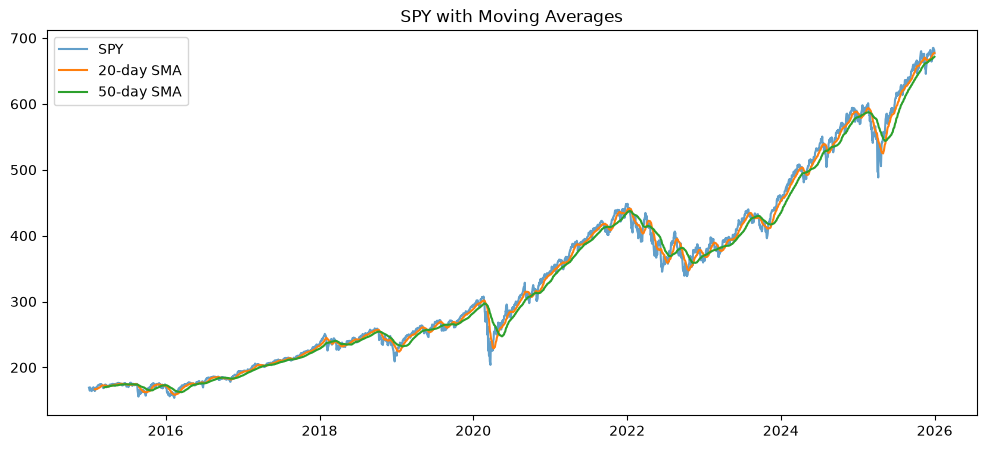

In [5]:
# plot indicators
plt.figure(figsize=(12, 5))

plt.plot(close, label="SPY", alpha=0.7)
plt.plot(df["SMA20"], label="20-day SMA")
plt.plot(df["SMA50"], label="50-day SMA")

plt.legend()
plt.title("SPY with Moving Averages")
plt.show()

### 4. Generate trading signals
Strategy (long only):
- SMA20 > SMA50: hold SPY (buy / hold SPY)
- SMA20 ≤ SMA50: hold cash (sell SPY / hold cash)
  
Signal is shifted to avoid look-ahead bias since closing price is used


In [6]:
# indicator function
df["Signal"] = (df["SMA20"] > df["SMA50"]).astype(int)

# take positions after signal observed
df["Position"] = df["Signal"].shift(1).fillna(0)

### 5. Calculate strategy returns
Assumptions: no slippage or txn costs, no interest earned on cash, no borrowing or leverage

In [7]:
# SPY daily return (today's price vs yesterday's price)
df["Market_Return"] = close.pct_change()

# strategy daily return (position * SPY daily return) - strategy only earns SPY returns when invested
df["Strategy_Return"] = (df["Position"] * df["Market_Return"])

df[["Market_Return", "Strategy_Return"]].head()

Price,Market_Return,Strategy_Return
Ticker,,
Date,,
2015-01-02,NaN,NaN
2015-01-05,-0.018060,-0.0
2015-01-06,-0.009419,-0.0
2015-01-07,0.012461,0.0
2015-01-08,0.017745,0.0


### 6. Compare against buy-and-hold
Calculate growth of $1 invested in each strategy

In [8]:
# first valid SMA50 date
first_valid = df["SMA50"].first_valid_index()
start_pos = df.index.get_loc(first_valid) + 1 # start trading one day later

# restrict both strategies to the same evaluation period
returns = df.iloc[start_pos:][["Market_Return", "Strategy_Return"]].dropna()

# compound returns to obtain cumulative growth of investment
equity = (1 + returns).cumprod() # cumulative product

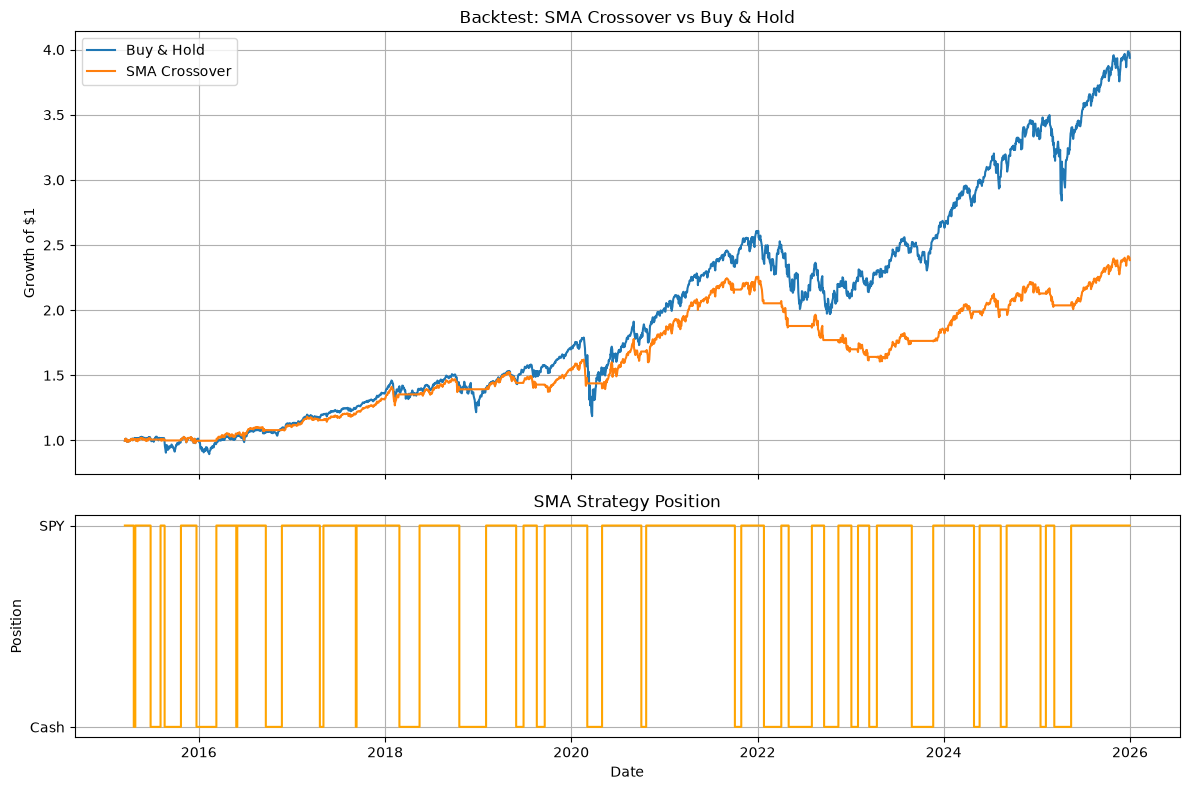

In [9]:
fig, axes = plt.subplots(2, 1,figsize=(12, 8),sharex=True,gridspec_kw={"height_ratios": [2, 1]})

# top: equity curves
axes[0].plot(equity.index,equity["Market_Return"],label="Buy & Hold")
axes[0].plot(equity.index,equity["Strategy_Return"],label="SMA Crossover")

axes[0].set_title("Backtest: SMA Crossover vs Buy & Hold")
axes[0].set_ylabel("Growth of $1")
axes[0].legend()
axes[0].grid(True)

# bottom: strategy position
axes[1].step(equity.index,df.loc[equity.index, "Position"],where="post",color="orange",label="SMA Position")

axes[1].set_title("SMA Strategy Position")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Position")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Cash", "SPY"])
axes[1].grid(True)

plt.tight_layout()
plt.savefig("results/sma_crossover.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# trading activity
# detect position changes
df["Trade"] = df["Position"].diff().fillna(0)

# count buys and sells
num_buys = (df["Trade"] == 1).sum()
num_sells = (df["Trade"] == -1).sum()

print("Number of buys:", num_buys)
print("Number of sells:", num_sells)
print("Total transactions:", num_buys + num_sells)

Number of buys: 26
Number of sells: 25
Total transactions: 51


### 7. Evaluate strategy performance 
- CAGR: Annualised compounded growth rate
- Annualised volatility: Standard deviation of daily returns, annualised
- Sharpe ratio (annualised): Excess return per unit of volatility (zero risk-free interest rate assumed)
- Maximum drawdown: Worst peak-to-trough loss
- Average market exposure: Proportion of time strategy is invested in SPY

In [11]:
def performance_metrics(returns, positions=None):
    returns = returns.dropna()
    equity = (1 + returns).cumprod()

    cagr = equity.iloc[-1] ** (252 / len(returns)) - 1
    volatility = returns.std() * np.sqrt(252)
    sharpe = (returns.mean() / returns.std() * np.sqrt(252) if returns.std() > 0 else np.nan)
    drawdown = equity / equity.cummax() - 1

    return {
        "CAGR": cagr,
        "Volatility": volatility,
        "Sharpe": sharpe,
        "Max Drawdown": drawdown.min(),
    }

In [12]:
results = pd.DataFrame({
    "Buy & Hold": performance_metrics(returns["Market_Return"]),
    "SMA Crossover": performance_metrics(returns["Strategy_Return"], positions=df["Position"])
}).T

results["Avg Exposure"] = [1.0,df.loc[returns.index, "Position"].mean()]

print(results.round(3))

                CAGR  Volatility  Sharpe  Max Drawdown  Avg Exposure
Buy & Hold     0.136       0.179   0.802        -0.337         1.000
SMA Crossover  0.084       0.113   0.769        -0.289         0.718


### 8. Interpret results
**Key Findings**
- Performance: SMA crossover strategy underperforms buy-and-hold, generating a CAGR of 8.4% vs 13.6%, and a slightly lower Sharpe ratio (0.769 vs 0.802)
- Risk: Strategy exhibits lower annusalised volatility (11.3% vs 17.9%) and a smaller maximum drawdown (28.9% vs 33.7%)
- Market exposure: Strategy was invested in SPY for 71.8% of trading days, suggesting that reduced market exposure may partially explain its lower volatility
- Trading activity: Strategy executed 51 transactions (26 buys and 25 sells), with transaction costs excluded from the backtest

**Limitations**
- Transaction costs, slippage, and realistic execution prices not modelled
- Uninvested cash earns zero interest, and Sharpe ratio assumes a zero risk-free rate
- No out-of-sample validation

**Conclusion**  
The SMA crossover strategy reduced volatility and meximum drawdown but failed to outperform buy-and-hold in both absolute and risk-adjusted returns. Further analysis required to determine whether lower volatility reflects effective market timing or simply reduced market exposure.